For immersion: https://www.youtube.com/watch?v=sdBrscwwy_c

# 🌟 Operation NeuroNexus

Trondheim lies under the iron grip of SkyNet, an AI system that has seized control of the city's entire digital infrastructure. You and your team of elite hackers have been tasked with a crucial mission: infiltrate SkyNet's systems, decode its defenses, and liberate the city from its digital oppressor.

## 🎯 Mission Overview

Operation NeuroNexus consists of four independent, yet interconnected missions. Each mission targets a different aspect of SkyNet's infrastructure and requires you to apply various Supervised Learning techniques covered in this course.

## 📊 Mission Structure

1. Each mission has a specific task related to combating SkyNet.
2. Following the task description, you'll find a set of formal requirements that your solution must meet.
3. The primary measure of your success is the accuracy of your machine learning model.
4. After completing each task, you must answer a series of questions to demonstrate your understanding of the techniques used.

## 🧪 A Note on Test Data

In a departure from real-world scenarios, you will have access to the target variables of the test sets for each mission. This has been arranged to facilitate the evaluation of your models. However, remember that in actual machine learning projects, test targets are not available, as predicting these is the ultimate goal of your supervised models.

## 📝 Submission Guidelines

- For each mission, provide your code solution and model results inside this notebook.
- Answer the follow-up questions in markdown format within this notebook. A few sentences is enough, no requirements for length of answers.
- Ensure your explanations are clear, concise, and demonstrate a deep understanding of the techniques employed.


Good luck! The resistance is counting on you.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

2025-08-27 13:21:13,177 - DEBUG - matplotlib - matplotlib data path: c:\Users\vegar\OneDrive - NTNU\Skule\Fag\IntroML\Kode\TDT4172SkyNett\.venv\Lib\site-packages\matplotlib\mpl-data
2025-08-27 13:21:13,185 - DEBUG - matplotlib - CONFIGDIR=C:\Users\vegar\.matplotlib
2025-08-27 13:21:13,199 - DEBUG - matplotlib - interactive is False
2025-08-27 13:21:13,201 - DEBUG - matplotlib - platform is win32
2025-08-27 13:21:13,287 - DEBUG - matplotlib - CACHEDIR=C:\Users\vegar\.matplotlib
2025-08-27 13:21:13,291 - DEBUG - matplotlib.font_manager - Using fontManager instance from C:\Users\vegar\.matplotlib\fontlist-v390.json


## 🌞 Mission 1: Predicting SkyNet's Power Consumption

### 🎯 The Mission
Intelligence suggests that SkyNet has a critical weakness: **its power consumption**. We must understand its energy needs to plan a coordinated strike.

### 🧠 Your Task
Develop a predictive model to estimate SkyNet's power consumption based on its **Network Activity**.

**Goal**: Implement a **Linear Regression model using Gradient Descent, from scratch**.

Use `LinearRegression` class from `linear_regression.py` stored in this folder. Your task is to complete two functions: `fit` (find the optimal parameters of the regression) and `predict` (apply them to the test data).

> Note: The `%autoreload` IPython magic command allows instant updates from `linear_regression.py`.

### 📊 Formal Requirements
1. **Implementation**: 
   - Use standard Python libraries (numpy, math, pandas, etc.)
   - Implement gradient descent

2. **Discussion**:

   a. Visualize the fitted curve. Derive the resulting Energy consumption formula.
   
   b. Analyze prediction error distribution. What is an unbiased estimator?

---

In [3]:
%load_ext autoreload
%autoreload 2

In [4]:
# Import your implementation
from sklearn.linear_model import LinearRegression as SkLinearRegression
from sklearn.model_selection import train_test_split
from linear_regression import LinearRegression # <--- This is your implementation

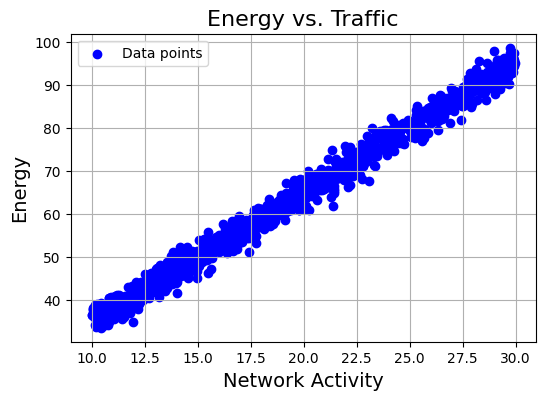

In [45]:
# Load data
data = pd.read_csv('mission1.csv')

plt.figure(figsize=(6, 4))
plt.scatter(data['Net_Activity'],data['Energy'], c='blue', label='Data points')
plt.grid(True)
plt.xlabel('Network Activity', fontsize=14)
plt.ylabel('Energy', fontsize=14)
plt.title('Energy vs. Traffic', fontsize=16)
plt.legend()
plt.show()



In [46]:
import pandas as pd

X = data['Net_Activity'].to_numpy().reshape(-1, 1)
y = data['Energy'].to_numpy()




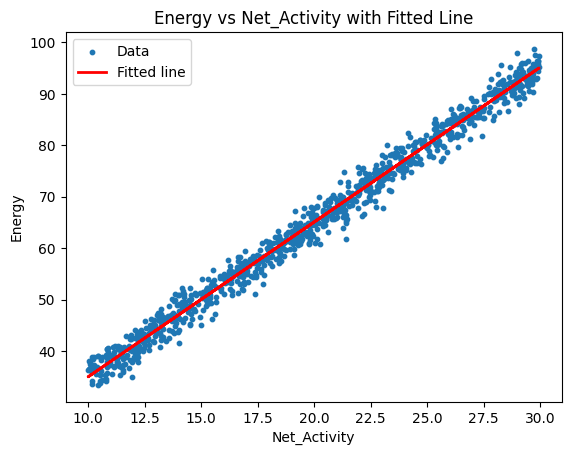

In [49]:
lr = LinearRegression()

lr.fit(data['Net_Activity'], data['Energy'])

y_hat = lr.predict(data['Net_Activity'])

plt.figure()
plt.scatter(X, y, s=10, label="Data")
plt.plot(X, y_hat, color="red", linewidth=2, label="Fitted line")
plt.xlabel("Net_Activity")
plt.ylabel("Energy")
plt.title("Energy vs Net_Activity with Fitted Line")
plt.legend()
plt.show()

## 🧠 Mission 2: Decoding SkyNet's signals

### 🌐 The Discovery
We've intercepted two types of signals that may determine SkyNet's next moves.

### 🎯 Your Mission
1. Evolve your linear regression into logistic regression
2. Engineer features to unravel hidden connections
3. Predict SkyNet's binary decisions (0 or 1) from paired signals

### 📊 Formal Requirements
1. **Implementation**: 
   - Use standard Python libraries
   - Implement gradient descent

2. **Performance**: Achieve at least 0.88 accuracy on the test set

3. **Discussion**:

   a. Explain poor initial performance and your improvements

      - The first model was a linear logistic regression model on the raw functions (x0,x1). This performed poorly (around 0.49-56% accuracy). This could be due to two reasons; Firstly, a linear decision limit may not pick up non-linear relations. Secondly the threshold used was a firm 0.5, which might not be ideal for non-balanced scenarios.
      This was mitigated by making the features quadratic by expanding the input from [x0,x1] to [x0,x1,x0x1,x0^2,x1^2] which makes the decision limit quadratic. 
      I also added slight L2 Regularization, standardized and early stopping to stabilize training

   b. What is the model's inductive bias. Why is it important?
      - Inductive bias refers to the set of assumptions that a learning algorithm makes to predict outputs for inputs it has never seen. This helps the model generalize to unseen data. A model with no bias or assumptions might fit the training data perfectly, capturing every minor detail, also known as overfitting.

   c. Try to solve the problem using `sklearn.tree.DecisionTreeClassifier`. Can it solve the problem? Why/Why not?
      - Most definitely. It builds partwise constant regions, and with enough depth the trees can approximate curved lines by "staircasing" itself around the correct area.
      
   d. Plot the ROC curve
      - Plotted below. Quite similar

---

In [ ]:
from logistic_regression import LogisticRegression
data = pd.read_csv('mission2.csv')
train = data[data['split'] == 'train']
test = data[data['split'] == 'test']

# Make validation set (20% of train, stratified)
val = train.groupby("y", group_keys=False).apply(lambda g: g.sample(frac=0.2, random_state=0))
train2 = train.drop(val.index)

X_tr  = train2[["x0","x1"]].to_numpy(float)
y_tr  = train2["y"].to_numpy(float)
X_val = val[["x0","x1"]].to_numpy(float)
y_val = val["y"].to_numpy(float)
X_te  = test[["x0","x1"]].to_numpy(float)
y_te  = test["y"].to_numpy(float)


Xtr2 = LogisticRegression.poly2(X_tr)
Xva2 = LogisticRegression.poly2(X_val)
Xte2 = LogisticRegression.poly2(X_te)

# Train model
model = LogisticRegression(n_iters=150_000, lr=0.05, lambda_l2=1e-3, grad_tol=1e-4)
model.fit(Xtr2, y_tr)

t_best, _ = model.find_best_threshold(Xva2, y_val, metric="accuracy")
acc_test  = model.score(Xte2, y_te, threshold=t_best)
print(f"Test accuracy: {acc_test:.3f}")

C:\Users\vegar\AppData\Local\Temp\ipykernel_13276\365772580.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  val = train.groupby("y", group_keys=False).apply(lambda g: g.sample(frac=0.2, random_state=0))
2025-08-29 15:22:35,149 - DEBUG - logistic_regression - iter=0 J=0.693147 ||g||=2.7991e-01
2025-08-29 15:22:35,184 - DEBUG - logistic_regression - iter=1000 J=0.443568 ||g||=1.5386e-02
2025-08-29 15:22:35,214 - DEBUG - logistic_regression - iter=2000 J=0.438944 ||g||=5.2224e-03
2025-08-29 15:22:35,243 - DEBUG - logistic_regression - iter=3000 J=0.438327 ||g||=2.0924e-03
2025-08-29 15:22:35,276 - DEBUG - logistic_regression - iter=4000 J=0.438223 ||g||=8.8424e-04
2025-08-29 15:22:35,309 - DEBUG - lo

Test accuracy: 0.902


In [71]:
from sklearn.tree import DecisionTreeClassifier
dtc = DecisionTreeClassifier(max_depth=5)
dtc.fit(train[["x0","x1"]], train["y"])
dtc_acc = dtc.score(test[["x0","x1"]], test["y"])
print(f"Decision Tree Test accuracy: {dtc_acc:.3f}")

Decision Tree Test accuracy: 0.918


c:\Users\vegar\OneDrive - NTNU\Skule\Fag\IntroML\Kode\TDT4172SkyNett\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


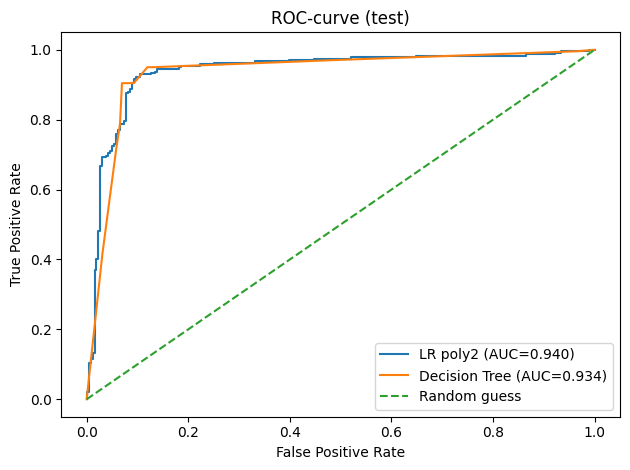

In [74]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Regression model
p_lr = model.predict(Xte2, return_proba=True)
auc_lr = roc_auc_score(y_te, p_lr)
fpr_lr, tpr_lr, _ = roc_curve(y_te, p_lr)

# Decision Tree
p_tree = dtc.predict_proba(X_te)[:, 1]
auc_tree = roc_auc_score(y_te, p_tree)
fpr_tr, tpr_tr, _ = roc_curve(y_te, p_tree)

plt.figure()
plt.plot(fpr_lr, tpr_lr, label=f"LR poly2 (AUC={auc_lr:.3f})")
plt.plot(fpr_tr, tpr_tr, label=f"Decision Tree (AUC={auc_tree:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-curve (test)")
plt.legend()
plt.tight_layout()
plt.show()


## 🌆 Mission 3: CyberGuard

### 🌐 The Discovery
SkyNet's drone communications use binary encryption. We need a system to intercept these messages.

### 🎯 Your Mission
Develop a decision tree classifier to process intercepted communications. Use `sklearn.tree.DecisionTreeClassifier`. 

Only one of the data streams needs to be decrypted, but you will need to identify the correct one.

To decrypt a data stream, transform the data into a binary representation based on whether the feature is even or odd.

### 📊 Formal Requirements
1. **Accuracy**: Achieve ROC AUC >= 0.72 on the test set
2. **Discussion**:

   a. Explain your threshold-breaking strategy. Did you change the default hyperparameters?

   b. Justify ROC AUC usage. Plot and interpret ROC.
   
   c. Try to solve the problem using sklearn’s Random Forest Classifier. Compare the results.

---

In [75]:
train_df = pd.read_csv('mission3_train.csv')
test_df = pd.read_csv('mission3_test.csv')

[CV] best mapping: {'auc': 0.6444442433162552, 'j': 3, 'col': 'data_stream_3', 's': 1000, 'o': 0.0, 'mode': 'half_up', 'abs': False}
Bit-features: 33968 columns
[VAL] best tree: (3, 1, 'gini') AUC= 0.642
[TEST] DecisionTree AUC=0.645  (goal ≥ 0.72)


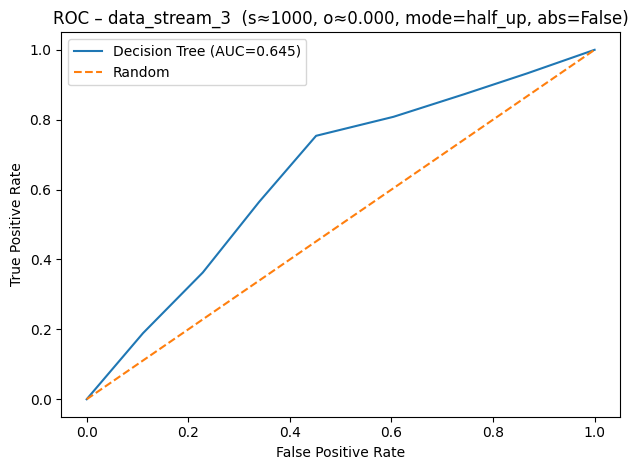

In [86]:
from sklearn.model_selection import StratifiedKFold

def round_half_up(x):
    s = np.sign(x)
    return s * np.floor(np.abs(x) + 0.5)

def quantize(x, mode):
    if mode=="round":      return np.rint(x)           
    if mode=="half_up":    return round_half_up(x)     
    if mode=="floor":      return np.floor(x)
    if mode=="ceil":       return np.ceil(x)
    if mode=="trunc":      return np.trunc(x)
    raise ValueError

def parity_bits(x, s=1.0, o=0.0, mode="half_up", use_abs=False):
    v = s*x + o
    ints = quantize(v, mode)
    if use_abs: ints = np.abs(ints)
    return (ints.astype(np.int64) & 1).astype(np.int8).reshape(-1,1)

# matrix of parity bits for all combinations
def make_parity_matrix(x, scales, offsets, modes, absops):
    feats=[]
    for s in scales:
        for o in offsets:
            for md in modes:
                for ab in absops:
                    b = parity_bits(x, s, o, md, ab)
                    if len(np.unique(b))==2:
                        feats.append(b)
    return np.hstack(feats) if feats else np.zeros((len(x),0), dtype=np.int8)

assert "target" in train_df.columns and "target" in test_df.columns

stream_cols = [c for c in train_df.columns if c.startswith("data_stream_")]

# strat. val (20%) 
val = train_df.groupby("target", group_keys=False).sample(frac=0.2, random_state=0)
train2 = train_df.drop(val.index)

X_tr  = train2[stream_cols].to_numpy(float); y_tr  = train2["target"].to_numpy(int)
X_va  = val[stream_cols].to_numpy(float);    y_va  = val["target"].to_numpy(int)
X_te  = test_df[stream_cols].to_numpy(float);y_te  = test_df["target"].to_numpy(int)

# -------- helpers --------
def round_half_up(x):
    s = np.sign(x); return s * np.floor(np.abs(x) + 0.5)
def quantize(x, mode):
    return {"half_up":round_half_up, "floor":np.floor, "ceil":np.ceil, "trunc":np.trunc}[mode](x)
def parity_bits(x, s=1.0, o=0.0, mode="half_up", use_abs=False):
    v = s*x + o
    ints = quantize(v, mode)
    if use_abs: ints = np.abs(ints)
    return (ints.astype(np.int64) & 1).astype(np.int8).reshape(-1,1)

def cv_auc_for_mapping(x, y, s, o, mode, ab, n_splits=5):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=0)
    aucs=[]
    for tr_idx, va_idx in skf.split(x, y):
        xb_tr, xb_va = parity_bits(x[tr_idx], s, o, mode, ab), parity_bits(x[va_idx], s, o, mode, ab)
        if len(np.unique(xb_tr))<2 or len(np.unique(xb_va))<2: return 0.5
        clf = DecisionTreeClassifier(max_depth=1, random_state=0)
        clf.fit(xb_tr, y[tr_idx])
        aucs.append(roc_auc_score(y[va_idx], clf.predict_proba(xb_va)[:,1]))
    return float(np.mean(aucs))

# Cv for best mapping per stream
coarse_scales  = [1,2,3,4,5,6,7,8,9,10,20,25,50,75,100,200,250,500,750,1000,2000,5000,10000,20000,50000,100000]
coarse_offsets = np.linspace(0.0, 0.95, 20)
modes   = ["half_up","floor","ceil","trunc"]
absops  = [False, True]

best = {"auc":-1}
for j, col in enumerate(stream_cols):
    xj = X_tr[:, j]
    for s in coarse_scales:
        for o in coarse_offsets:
            for md in modes:
                for ab in absops:
                    auc = cv_auc_for_mapping(xj, y_tr, s, o, md, ab, n_splits=5)
                    if auc > best["auc"]:
                        best = {"auc":auc, "j":j, "col":col, "s":s, "o":float(o), "mode":md, "abs":ab}
print("[CV] best mapping:", best)

# Build bit-features for best stream
j = best["j"]; x_tr_j, x_va_j, x_te_j = X_tr[:,j], X_va[:,j], X_te[:,j]

scales  = sorted(set([best["s"] + k for k in range(-50,51)] + [best["s"]*m for m in [1,2,3,5,10] if best["s"]*m<=1_000_000]))
offsets = sorted(set(np.round(np.linspace(0,1,41),3).tolist() + [best["o"]]))
modes_b = ["half_up","floor","trunc","ceil"]
abs_b   = [best["abs"], not best["abs"]]

def make_parity_matrix(x):
    feats=[]
    for s in scales:
        for o in offsets:
            for md in modes_b:
                for ab in abs_b:
                    b = parity_bits(x, s, o, md, ab)
                    if len(np.unique(b))==2: feats.append(b)
    return np.hstack(feats) if feats else np.zeros((len(x),0), dtype=np.int8)

Bx_tr, Bx_va, Bx_te = make_parity_matrix(x_tr_j), make_parity_matrix(x_va_j), make_parity_matrix(x_te_j)
print("Bit-features:", Bx_tr.shape[1], "columns")

# tune decision tree on val
best_auc, best_h, best_clf = -1, None, None
for depth in [2,3,4,5,6,8,10,12,16,20]:
    for msl in [1,2,5,10,20,50]:
        for crit in ["gini","entropy"]:
            clf = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=msl, criterion=crit, random_state=0)
            clf.fit(Bx_tr, y_tr)
            auc = roc_auc_score(y_va, clf.predict_proba(Bx_va)[:,1])
            if auc > best_auc:
                best_auc, best_h, best_clf = auc, (depth, msl, crit), clf
print("[VAL] best tree:", best_h, "AUC=", round(best_auc,3))

# train final on train+val, eval on test
Bx_trval = np.vstack([Bx_tr, Bx_va]); y_trval = np.r_[y_tr, y_va]
final = DecisionTreeClassifier(max_depth=best_h[0], min_samples_leaf=best_h[1], criterion=best_h[2], random_state=0)
final.fit(Bx_trval, y_trval)

p_te = final.predict_proba(Bx_te)[:,1]
auc_te = roc_auc_score(y_te, p_te)
print(f"[TEST] DecisionTree AUC={auc_te:.3f}  (goal ≥ 0.72)")

fpr, tpr, _ = roc_curve(y_te, p_te)
plt.figure()
plt.plot(fpr, tpr, label=f"Decision Tree (AUC={auc_te:.3f})")
plt.plot([0,1],[0,1],"--", label="Random")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title(f"ROC – {stream_cols[j]}  (s≈{best['s']}, o≈{best['o']:.3f}, mode={best['mode']}, abs={best['abs']})")
plt.legend(); plt.tight_layout(); plt.show()

## ⚡ Final Mission: Mapping SkyNet's Energy Nexus

### 🌐 The Discovery
SkyNet is harvesting energy from Trondheim's buildings. Some structures provide significantly more power than others.

### 🎯 Your Mission
Predict the **Nexus Rating** of unknown buildings in Trondheim (test set).

### 🧠 The Challenge
1. **Target**: Transform the Nexus Rating to reveal true energy hierarchy
2. **Data Quality**: Handle missing values and categorical features
3. **Ensembling**: Use advanced models and ensemble learning

### 💡 Hint
You suspect that an insider has tampered with the columns in the testing data... 

Compare the training and test distributions and try to rectify the test dataset.

### 📊 Formal Requirements
1. **Performance**: Achieve RMSLE <= 0.294 on the test set
2. **Discussion**:

   a. Explain your threshold-breaking strategy

   b. Justify RMSLE usage. Why do we use this metric? Which loss function did you use?

   c. Plot and interpret feature importances

   d. Describe your ensembling techniques

   e. In real life, you do not have the test targets. How would you make sure your model will work good on the unseen data? 

---

In [8]:
train = pd.read_csv('final_mission_train.csv')
test = pd.read_csv('final_mission_test.csv')

Text(0, 0.5, 'Count')

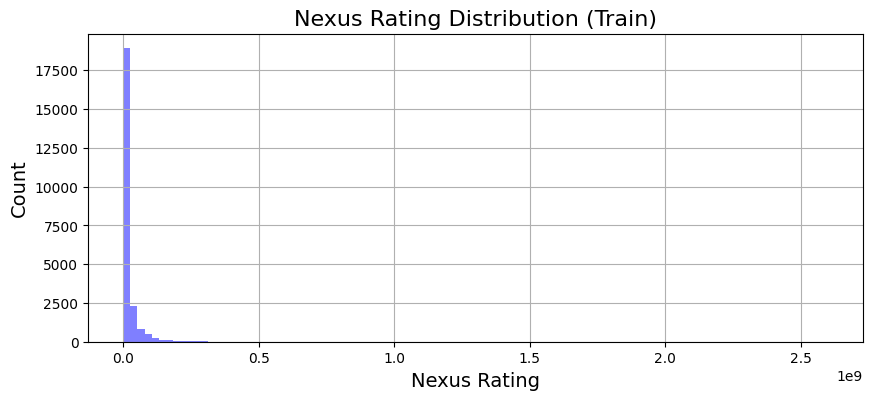

In [9]:
fig, ax = plt.subplots(1, 1, figsize=(10, 4))
train['nexus_rating'].hist(bins=100, ax=ax, color='blue', alpha=0.5, label='Train Target Distributuon')
ax.set_title('Nexus Rating Distribution (Train)', fontsize=16)
ax.set_xlabel('Nexus Rating', fontsize=14)
ax.set_ylabel('Count', fontsize=14)

In [10]:
from sklearn.metrics import mean_squared_log_error

def rmsle(y_true, y_pred):
    """ Root Mean Squared Logarithmic Error """
    return np.sqrt(mean_squared_log_error(y_true, y_pred))

In [ ]:
# Example rmsle check
test['pred'] = 0
print('RMSLE: ', rmsle(test['nexus_rating'], test['pred']))
print('Required RMSLE: ', 0.294)

RMSLE:  4.203250078450383
Required RMSLE:  0.294
